# Latihan SKLearn SVR (Support Vector Regression)

- **Dataset**: [`Salary_Data.csv`](https://www.kaggle.com/karthickveerakumar/salary-data-simple-linear-regression) (30 data lama kerja `YearsExperience` dan gaji `Salary`)
- **Referensi Materi**: [Latihan SKLearn SVR (Notion)](https://app.notion.com/p/Latihan-SKLearn-SVR-277e27a5dc7b812e837fe611bdf56998)

## Tujuan

Setelah mengenal *Support Vector Regression* (SVR), pada latihan ini kita akan belajar menerapkan teknik regresi berbasis SVM tersebut ke dalam model *machine learning* menggunakan *library* `scikit-learn`.

## Tahapan Latihan

Tahapan pada latihan kali ini adalah sebagai berikut:

1. Ubah data menjadi DataFrame.
2. Pisahkan atribut dan label.
3. Latih model SVR.
4. Buat plot dari model.

## Codelab

Dataset yang digunakan berisi data lama pengalaman kerja (`YearsExperience`) dan gaji seseorang (`Salary`) dari berkas `Salary_Data.csv` yang tersedia pada folder yang sama dengan notebook ini. Pada tahap pertama, kita mengimpor `pandas` dan membaca berkas CSV ke dalam DataFrame.

In [1]:
import pandas as pd

# membaca dataset dan mengubahnya menjadi dataframe
data = pd.read_csv('Salary_Data.csv')

Selanjutnya kita periksa apakah terdapat *missing value* dan cek tipe data tiap kolom menggunakan fungsi `.info()`. Keluaran `.info()` akan menunjukkan apakah seluruh entri lengkap dan bertipe numerik.

In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


Selanjutnya kita tampilkan 5 baris pertama dari DataFrame menggunakan `data.head()` untuk melihat contoh isi datanya.

In [3]:
data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


Kemudian kita pisahkan antara atribut (`YearsExperience`) dan label target (`Salary`). Karena hanya terdapat satu kolom fitur pada DataFrame, vektor atribut perlu diubah bentuknya menjadi array 2 dimensi (`(n_samples, 1)`) menggunakan `np.newaxis` agar dapat diproses oleh estimator `scikit-learn`.

In [4]:
import numpy as np

# memisahkan atribut dan label
X = data['YearsExperience']
y = data['Salary']

# mengubah bentuk atribut
X = np.array(X)
X = X[:, np.newaxis]

Berikutnya kita membuat objek *Support Vector Regression* (`SVR`) dengan parameter `C=1000`, `gamma=0.05`, dan `kernel='rbf'`, lalu melatih model menggunakan fungsi `.fit(X, y)`.

In [5]:
from sklearn.svm import SVR

# membangun model dengan parameter C, gamma, dan kernel
model = SVR(C=1000, gamma=0.05, kernel='rbf')

# melatih model dengan fungsi fit
model.fit(X, y)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.05
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


Terakhir, kita memvisualisasikan sebaran data aktual (*scatter plot*) beserta kurva prediksi dari model SVR menggunakan `matplotlib` untuk melihat seberapa baik model menyesuaikan pola data.

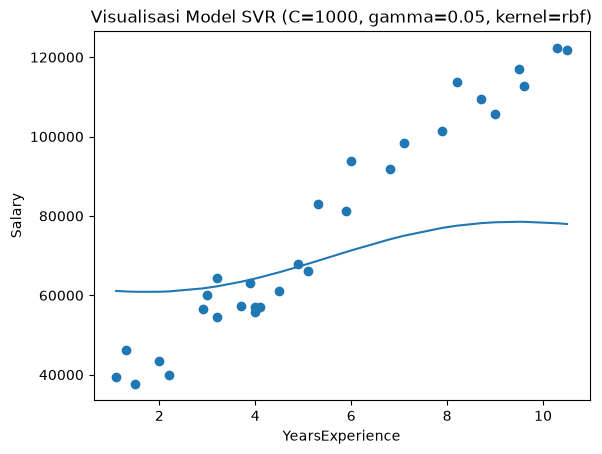

In [6]:
import matplotlib.pyplot as plt

# memvisualisasikan model
plt.scatter(X, y)
plt.plot(X, model.predict(X))
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('Visualisasi Model SVR (C=1000, gamma=0.05, kernel=rbf)')
plt.show()

## Kesimpulan

Hasil visualisasi menunjukkan bahwa model SVR dengan konfigurasi `C=1000`, `gamma=0.05`, dan `kernel='rbf'` belum mampu menyesuaikan pola linear data gaji dengan baik (kurva prediksi masih cenderung datar/underfitting terhadap rentang nilai `Salary` yang besar). Pada tahap pengembangan berikutnya, pemilihan kombinasi hyperparameter `C` dan `gamma` dapat dioptimalkan menggunakan teknik *Grid Search*.